(ambient_rna)=

# Ambient RNA removal

Droplets capture cell-free mRNA from the cell suspension together with their cell. This ambient
RNA, the soup, comes from cells that lysed before or during loading, so every droplet holds some
of it, including droplets without a cell. A cell then shows counts of genes it does not express,
such as haemoglobin from red blood cells or immunoglobulins from plasma and B cells. These counts
add apparent expression of other cell types' markers and can blur differential expression.

CyteArc follows SoupX as Young and Behjati describe it [@Young_2020] in three steps:

1. `qc.ambient_profile` estimates the composition of the soup from droplets that hold no cell.
2. `qc.ambient_contamination` measures the fraction of each cell's counts that come from the
   soup, using genes that some cells cannot express.
3. `qc.correct_ambient` removes each cell's share of soup counts and writes the result as a new
   assay of integer counts.

The first two steps save immutable results with provenance. The third writes a new RNA assay that
every analysis can use by name. The method needs the unfiltered droplets of each channel, not
only the barcodes that Cell Ranger called as cells.

## Download a raw and filtered matrix pair

We use the 10x Genomics dataset "1k PBMCs from a Healthy Donor (v2 chemistry)", published under
CC BY 4.0. The raw matrix (18 MB) holds every barcode with at least one count, and the filtered
matrix (3 MB) holds the barcodes that Cell Ranger called as cells. We use the filtered matrix only
for its list of cell barcodes.

The example uses a temporary directory. Use a project directory instead if you want to keep the
downloaded files and Zarr store after closing the notebook.

In [1]:
# Download and verify the published matrices.
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import Request, urlopen

# Read the called barcodes and summarize the results.
import h5py
import numpy as np
import pandas as pd
import cytearc

# Display the diagnostic figures.
import matplotlib.pyplot as plt

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-10-22T16:51:48.370310Z | Wall time: 1.268 s

In [2]:
# Pin both files so that a changed download cannot alter the example silently.
base_url = "https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_1k_v2/"
sources = {
    "raw": (
        "pbmc_1k_v2_raw_feature_bc_matrix.h5",
        "fd258b397faf0e38eed00f8f06f6068cd380963d15e90e25a67c5cd9e19e4f71",
    ),
    "filtered": (
        "pbmc_1k_v2_filtered_feature_bc_matrix.h5",
        "344673d4eca5af4b4f8343ef85c039fa5b24fea75a7d714a54427548b7b60213",
    ),
}
paths = {}
for name, (file_name, expected_digest) in sources.items():
    path = output_dir / file_name

    # Name the client, because the host refuses Python's default one.
    request = Request(base_url + file_name, headers={"User-Agent": "CyteArc documentation"})

    # Copy the response in blocks without holding the file in memory.
    with urlopen(request, timeout=60) as response, path.open("wb") as target:
        shutil.copyfileobj(response, target)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(1)

raw         18.4
filtered     3.4
Name: Downloaded MB, dtype: float64

Started: 2026-10-22T16:51:49.641616Z | Wall time: 1.871 s

## Import every droplet

The soup profile needs droplets without a cell, so import the raw matrix rather than the
filtered one. `CrH5Reader(is_filtered=False)` keeps the barcodes whose total count exceeds
`filtering_cutoff`; a cutoff of 1 keeps every droplet with at least two counts, the smallest
droplets that the profile uses. Most barcodes of a raw matrix hold only a few counts. The default
feature floor of the first open would remove most of them, so it removes none and warns instead;
`min_features_per_cell=-1` keeps them all active without the warning.

The import writes the counts of tens of thousands of droplets and takes a few minutes.

In [3]:
# Write every barcode with at least two counts into a new store.
store_path = output_dir / "pbmc_1k_v2_droplets.zarr"
cytearc.CrToZarr(
    cytearc.CrH5Reader(str(paths["raw"]), is_filtered=False, filtering_cutoff=1),
    zarr_loc=str(store_path),
    nthreads=4,
    mem_budget="4G",
).dump()

# Open the store without removing barcodes with few features.
ds = cytearc.DataStore(
    str(store_path),
    default_assay="RNA",
    min_features_per_cell=-1,
    nthreads=4,
    mem_budget="4G",
)

# Mark the barcodes that Cell Ranger called as cells.
with h5py.File(paths["filtered"], "r") as handle:
    called = handle["matrix/barcodes"][:].astype(str)
ds.cells.insert("cell_ranger_cell", np.isin(ds.cells.fetch_all("ids").astype(str), called))

# Count the droplets and the cells among them.
totals = ds.cells.fetch_all("RNA_nCounts")
is_cell = ds.cells.fetch_all("cell_ranger_cell")
pd.Series(
    {
        "Barcodes": ds.cells.N,
        "Called cells": int(is_cell.sum()),
        "Droplets with 2 to 10 counts": int(((totals >= 2) & (totals <= 10)).sum()),
    },
    name="Barcodes",
)

Barcodes                        93338
Called cells                      996
Droplets with 2 to 10 counts    79891
Name: Barcodes, dtype: int64

Started: 2026-10-22T16:51:51.514838Z | Wall time: 114.617 s

The barcode rank plot orders the droplets by their total count. Cells form the plateau at the
top. Below the steep drop lie droplets with soup alone, and the shaded band marks the 2 to 10
counts that the paper uses for the soup profile.

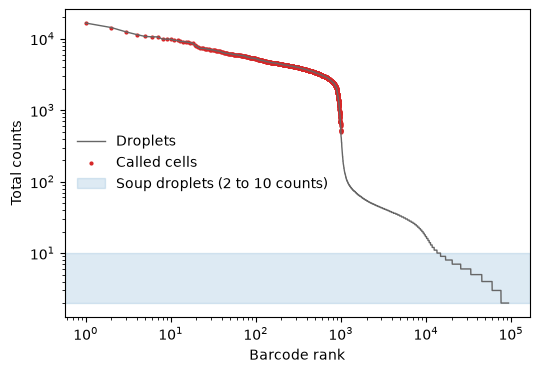

Started: 2026-10-22T16:53:46.135892Z | Wall time: 0.373 s

In [4]:
# Order the droplets by their total count, largest first.
order = np.argsort(totals)[::-1]
ranks = np.arange(1, len(order) + 1)

# Plot every droplet and mark the called cells.
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ranks, totals[order], color="0.4", linewidth=1, label="Droplets")
ax.scatter(
    ranks[is_cell[order]],
    totals[order][is_cell[order]],
    s=4,
    color="tab:red",
    label="Called cells",
)

# Shade the total counts of the droplets that define the soup.
ax.axhspan(2, 10, color="tab:blue", alpha=0.15, label="Soup droplets (2 to 10 counts)")
ax.set(xscale="log", yscale="log", xlabel="Barcode rank", ylabel="Total counts")
ax.legend(frameon=False)
plt.show()

## Estimate the soup profile

`qc.ambient_profile` sums the counts of the chosen droplets in one bounded pass and stores each
gene's share of them. Choose the droplets with `total_counts=(low, high)`, an inclusive range
of total counts, or with `empty_droplets=`, a cell selection of empty barcodes. The paper uses
droplets with 2 to 10 counts and leaves out droplets with one count, whose barcodes may be
sequencing errors; profiles from droplets with up to about 100 counts agreed well with it.

In [5]:
# Sum the counts of the droplets with 2 to 10 counts.
profile = ds.qc.ambient_profile(total_counts=(2, 10))
soup = ds.qc.load_ambient_profile(profile)

# Show the genes that dominate the soup.
print(
    f"{soup.attrs['n_droplets']:,} droplets hold {soup.attrs['n_counts']:,} soup counts"
)
soup.sort_values("fraction", ascending=False).head(10)

79,891 droplets hold 344,712 soup counts


,name,counts,fraction
ids,,,
ENSG00000251562,MALAT1,10602,0.030756
ENSG00000205542,TMSB4X,5756,0.016698
ENSG00000166710,B2M,5438,0.015775
ENSG00000156508,EEF1A1,4357,0.012640
ENSG00000147403,RPL10,3842,0.011146
ENSG00000177954,RPS27,3797,0.011015
ENSG00000122026,RPL21,3462,0.010043
ENSG00000167526,RPL13,3429,0.009947
ENSG00000229117,RPL41,3321,0.009634


Started: 2026-10-22T16:53:46.511504Z | Wall time: 7.720 s

Abundant transcripts of every cell type, such as `MALAT1`, `B2M`, and ribosomal protein genes,
dominate the soup. Transcripts of abundant cell types follow, so the soup resembles the pooled
expression of the cells that lysed.

## Cluster the cells

The contamination estimate leaves out every cell of a cluster that expresses a marker gene set,
so it needs cluster labels for the cells. A pipeline run on the called cells provides them.
Filtering is switched off so that every called cell gets a label, and the run's marker search
names the clusters.

In [6]:
# Cluster the called cells without filtering any of them.
run = ds.pipeline.run(
    label="called_cells",
    cell_key="cell_ranger_cell",
    filtering=False,
    cell_cycle=False,
    paris=False,
    doublets=False,
)
cells = run["analysis_cell_selection"]
clusters = run["clusters"]

# Name each cluster by its strongest markers.
labels = ds.artifacts.load_values(clusters).to_pandas()
markers = ds.markers.load(marker=run["markers"])
top_markers = markers.groupby("group_id", sort=False)["feature_name"].agg(
    lambda names: ", ".join(names.head(4))
)
pd.DataFrame(
    {
        "Cells": labels.value_counts().sort_index(),
        "Top markers": top_markers.set_axis(top_markers.index.astype(labels.dtype)),
    }
)

,Cells,Top markers
1,283,"S100A12, VCAN, CD14, AC020656.1"
2,177,"LEF1, CCR7, TRABD2A, MAL"
3,158,"MAL, PASK, CD5, AQP3"
4,142,"CD79A, MS4A1, IGHM, IGHD"
5,94,"GZMK, TRGC2, LINC01871, CD8A"
6,73,"KLRF1, KLRD1, SPON2, GNLY"
7,35,"FCER1A, NRGN, PPBP, PLD4"
8,34,"CSF1R, SMIM25, MS4A7, TCF7L2"


Started: 2026-10-22T16:53:54.233508Z | Wall time: 82.848 s

## Estimate the contamination fraction

The contamination fraction is measured with genes that some cells cannot express. In a cell
without endogenous expression of a gene set, every count of the set comes from the soup, so the
ratio of its observed counts to the counts that a droplet of pure soup with the same total
would hold is the contamination fraction. Haemoglobin genes, outside red blood cells, and
immunoglobulin genes, outside B and plasma cells, are the usual choices for blood.

For each gene set, a cell expresses the set when its count is significantly larger than pure
soup could give it: a Poisson test at the largest plausible contamination, `max_contamination`
(1 by default), with a Benjamini-Hochberg false discovery rate of `fdr` (0.05). The estimate
leaves out those cells and every other cell of their clusters, then pools the remaining cells
and gene sets.

In [7]:
# Keep the haemoglobin and immunoglobulin genes that the assay measures.
feature_names = set(ds.RNA.feats.fetch_all("names").astype(str))
gene_sets = {
    "haemoglobin": ["HBA1", "HBA2", "HBB", "HBD", "HBG1", "HBG2", "HBM", "HBQ1", "HBZ"],
    "immunoglobulin": [
        "IGKC", "IGHM", "IGHD", "IGHA1", "IGHA2", "IGHG1", "IGHG2", "IGHG3", "IGHG4",
        "IGLC1", "IGLC2", "IGLC3", "IGLC7", "JCHAIN",
    ],
}
gene_sets = {
    name: [gene for gene in genes if gene in feature_names]
    for name, genes in gene_sets.items()
}

# Estimate one contamination fraction from both gene sets.
estimate = ds.qc.ambient_contamination(
    cells, profile, gene_sets=gene_sets, clusters=clusters
)
contamination = ds.qc.load_ambient_contamination(estimate)
pd.Series(
    {"All gene sets": contamination.estimate, **contamination.set_estimates},
    name="Contamination fraction",
).round(4)

All gene sets     0.0111
haemoglobin       0.0119
immunoglobulin    0.0110
Name: Contamination fraction, dtype: float64

Started: 2026-10-22T16:55:17.083715Z | Wall time: 2.508 s

About one percent of each cell's counts come from the soup in this dataset, and the two gene
sets agree. The evidence shows which cells measured it. The B-cell cluster 4 expresses the
immunoglobulin genes, so it is left out of that set. Cluster 7 has five cells that express the
haemoglobin genes and five that express the immunoglobulin genes, so it is left out of both sets.
That is why the per-cluster estimate below fails for it.

In [8]:
# Count, for each cluster, the cells that express each set and the cells that measured it.
evidence = contamination.evidence.assign(
    cluster=labels.reindex(contamination.evidence["ids"]).to_numpy()
)
evidence.pivot_table(
    index="cluster",
    columns="gene_set",
    values=["expressing", "used"],
    aggfunc="sum",
)

expressing                       used               
gene_set haemoglobin immunoglobulin haemoglobin immunoglobulin
cluster                                                       
1                  0              0         283            283
2                  0              0         177            177
3                  0              0         158            158
4                  0            138         142              0
5                  0              0          94             94
6                  0              0          73             73
7                  5              5           0              0
8                  0              0          34             34

Started: 2026-10-22T16:55:19.593018Z | Wall time: 0.012 s

Leaving out whole clusters matters. Without `clusters=`, only the cells that pass the test are
left out, and cells whose expression is real but too weak to pass it inflate the estimate:

In [9]:
# Estimate again without cluster labels.
cells_only = ds.qc.load_ambient_contamination(
    ds.qc.ambient_contamination(cells, profile, gene_sets=gene_sets)
)
pd.Series(
    {"With clusters": contamination.estimate, "Without clusters": cells_only.estimate},
    name="Contamination fraction",
).round(4)

With clusters       0.0111
Without clusters    0.0246
Name: Contamination fraction, dtype: float64

Started: 2026-10-22T16:55:19.607020Z | Wall time: 2.109 s

`level="cluster"` estimates each cluster from its own cells instead. Each cluster then needs a
gene set that it does not express, and a cluster that expresses every set raises an error that
names it. The paper finds a global estimate sufficient in most cases.

In [10]:
# Try one estimate for each cluster.
try:
    per_cluster = ds.qc.load_ambient_contamination(
        ds.qc.ambient_contamination(
            cells, profile, gene_sets=gene_sets, clusters=clusters, level="cluster"
        )
    )
    print(pd.Series(per_cluster.cluster_estimates, name="Contamination fraction"))
except ValueError as error:
    print(error)

These clusters have no cell that can measure the contamination, because they express every gene set: 7. Add a gene set that they do not express, or use level='global'.


Started: 2026-10-22T16:55:21.718460Z | Wall time: 2.022 s

When no suitable gene set is known, pass a known fraction for every cell with `fraction=` instead
of `gene_sets=`.

## Remove the ambient counts

`qc.correct_ambient` removes each cell's contamination fraction of its counts. The removal is the
most likely one under a multinomial model with the soup's gene fractions that never removes more
of a gene than the cell holds: genes are emptied in increasing order of their count divided by
their soup fraction, and the rest is taken from the other genes in proportion to their soup
fraction. Genes absent from the soup keep every count.

Most genes are due far less than one count in a cell, so the removal must be rounded to whole
counts. As in the paper, each gene's removal is rounded up at random with a probability equal to
its fractional part: a gene due 0.2 counts in each cell loses one count in about a fifth of the
cells, so summed over the cells every gene loses its share of the soup, however small. The draws
follow systematic sampling with one draw per cell, so each cell loses its share rounded down or
up, and the corrected counts never exceed the raw counts. `random_seed`, 0 by default, sets the
draws, so a repeated correction gives the same counts.

The new assay has a row for every barcode but measures only the corrected cells, which its
membership column `RNA_soupx_I` records; the other rows hold no counts.

In [11]:
# Write the corrected counts as a new RNA assay.
ds.qc.correct_ambient(estimate, assay_label="RNA_soupx")

# Compare each cell's total before and after the correction.
removed = (
    ds.cells.fetch_all("RNA_nCounts") - ds.cells.fetch_all("RNA_soupx_nCounts")
)[is_cell] / totals[is_cell]
pd.Series(removed, name="Share of counts removed").describe().round(4)

count    996.0000
mean       0.0111
std        0.0002
min        0.0097
25%        0.0110
50%        0.0111
75%        0.0111
max        0.0119
Name: Share of counts removed, dtype: float64

Started: 2026-10-22T16:55:23.742003Z | Wall time: 9.733 s

## Compare markers before and after

Ambient counts appear as low expression of one cell type's markers in other cell types. The
monocyte markers `S100A9` and `LYZ` are among the most abundant genes of the soup, while the
immunoglobulin `IGKC` holds a smaller share of it.

In [12]:
# Rank the compared markers among the genes of the soup.
compared = ["S100A9", "LYZ", "IGKC"]
soup_rank = soup["fraction"].rank(ascending=False, method="min").astype(int)
pd.DataFrame(
    {"Soup fraction": soup["fraction"], "Rank in the soup": soup_rank}
).set_index(soup["name"]).loc[compared]

,Soup fraction,Rank in the soup
name,,
S100A9,0.005367,34
LYZ,0.004375,44
IGKC,0.000853,157


Started: 2026-10-22T16:55:33.476290Z | Wall time: 0.011 s

The table shows the percentage of each cluster's cells that hold any count of these markers, in
the raw and the corrected counts.

In [13]:
# Read the raw and corrected counts of the markers for the called cells.
counts = {
    name: ds.to_anndata(from_assay=assay, cell_key="cell_ranger_cell", feature_names=compared)
    for name, assay in (("Raw", "RNA"), ("Corrected", "RNA_soupx"))
}
cell_clusters = labels.reindex(counts["Raw"].obs_names).to_numpy()

# Report the percentage of each cluster's cells that hold each marker.
detected = pd.concat(
    {
        name: 100
        * pd.DataFrame(data.X.toarray() > 0, columns=compared).groupby(cell_clusters).mean()
        for name, data in counts.items()
    },
    axis=1,
).swaplevel(axis=1)[compared]
detected.index.name = "cluster"
detected.round(1)

S100A9              LYZ            IGKC          
           Raw Corrected    Raw Corrected   Raw Corrected
cluster                                                  
1        100.0     100.0  100.0     100.0   4.9       4.6
2         17.5      13.6   16.9      11.3   2.8       2.8
3         18.4      13.9   11.4       7.6   3.2       3.2
4         18.3      16.2    7.7       4.9  72.5      72.5
5         19.1      16.0   10.6       9.6   1.1       1.1
6         16.4      12.3   16.4      15.1   0.0       0.0
7         62.9      62.9   60.0      60.0  20.0      20.0
8         82.4      82.4   91.2      79.4  11.8       5.9

Started: 2026-10-22T16:55:33.489106Z | Wall time: 1.917 s

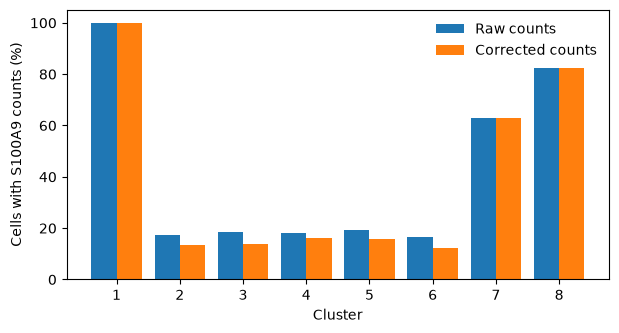

Started: 2026-10-22T16:55:35.408452Z | Wall time: 0.101 s

In [14]:
# Plot the cells with S100A9 counts in each cluster before and after the correction.
positions = np.arange(len(detected))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(positions - 0.2, detected[("S100A9", "Raw")], width=0.4, label="Raw counts")
ax.bar(positions + 0.2, detected[("S100A9", "Corrected")], width=0.4, label="Corrected counts")
ax.set_xticks(positions, detected.index)
ax.set(xlabel="Cluster", ylabel="Cells with S100A9 counts (%)")
ax.legend(frameon=False)
plt.show()

In the lymphocyte clusters, fewer cells keep `S100A9` and `LYZ` counts after the correction.
Cells that express these genes at high levels, such as classical monocytes, keep them, while a
cell with only a few counts can lose them, because the correction cannot tell a cell's own few
counts from the soup's. `IGKC` changes little: only three cells lose it, one in cluster 1 and
two in cluster 8. The correction takes counts in proportion to the soup, and with about one
percent contamination a cell's expected soup count of `IGKC` is far below one: a cell loses its
`IGKC` count with that small probability, so a single `IGKC` count in a T cell usually stays.
Summed over the cells, the correction removes the soup's expected share of each gene, not every
count of a marker in the wrong cell type.

## Use the corrected counts

The corrected assay is an RNA assay with `countsT`, so every analysis takes it by name, such as
`ds.pipeline.run(assay="RNA_soupx", cell_key="cell_ranger_cell")`, `from_assay="RNA_soupx"` in
plots and marker searches, or `ds.features.universe(from_assay="RNA_soupx")`. Select the corrected
cells: the assay did not measure the other barcodes, and analyses refuse them.

## Corrected counts from other tools

[CellBender](https://github.com/broadinstitute/CellBender) removes ambient RNA with a generative
model and writes its corrected counts in the Cell Ranger HDF5 layout. Import that file with
`cytearc.CrToZarr(cytearc.CrH5Reader("cellbender_output_filtered.h5"), zarr_loc=...)` as you would
a Cell Ranger matrix. Its counts are then ordinary counts of a store, without the provenance of
the steps above.

## Common mistakes and limitations

- A soup profile from droplets that hold cells is not a soup profile. Keep the count range below
  the cells, as the barcode rank plot shows, and import the raw matrix, not the filtered one.
- A gene set that every cluster expresses measures nothing: every cell is left out. Choose genes
  that are specific to a few cell types and abundant in the soup.
- Without clusters, weakly expressing cells raise the estimate. Pass a clustering of the cells.
- The correction removes counts in proportion to the soup's composition; it cannot tell which
  molecule of a gene came from the soup. Genes that are abundant in the soup lose counts in every
  cell, including cells that express them.
- The rounding is random: another `random_seed` takes a gene's rare soup counts from other cells.
  A conclusion that rests on a few counts of a gene should hold for another seed.
- Estimate each channel separately: each channel has its own soup. One profile and estimate
  correct one set of cells into one assay.
- The paper's automatic estimate, its hierarchical model of cell-level fractions, and its
  correction of counts aggregated within clusters are not implemented.